In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("/content/sample_data/new.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


# EDA

In [4]:
df.shape

(2240, 29)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [6]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


### Data preprocessing

In [9]:
drop_cols = [
    "ID",
    "Z_CostContact",
    "Z_Revenue"
]

df = df.drop(columns=drop_cols)

# this are running tommorow..

 ### Convert date into useful features

In [10]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

df["CustomerYear"] = df["Dt_Customer"].dt.year
df["CustomerMonth"] = df["Dt_Customer"].dt.month

In [11]:
reference_date = df["Dt_Customer"].max()

df["CustomerTenureDays"] = (
    reference_date - df["Dt_Customer"]
).dt.days

In [12]:
df = df.drop(columns=["Dt_Customer"]) # drop original column

### Feature engineering

#### Total Spend

In [13]:
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["TotalSpend"] = df[spending_cols].sum(axis=1)

#### Total purchases

In [14]:
purchase_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

df["TotalPurchases"] = df[purchase_cols].sum(axis=1)

In [15]:
df["TotalChildren"] = df["Kidhome"] + df["Teenhome"]

### Total Campaing Accepted

In [16]:
campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

df["TotalCampaignAccepted"] = df[campaign_cols].sum(axis=1)

In [17]:
reference_year = 2026

df["Age"] = reference_year - df["Year_Birth"]

In [18]:
df = df.drop(columns=["Year_Birth"])

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt


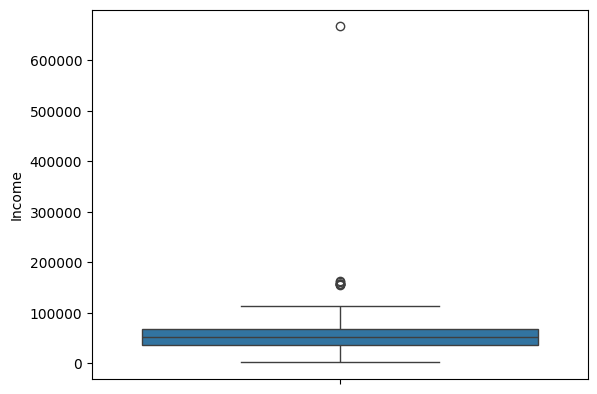

<Figure size 1000x800 with 0 Axes>

In [20]:
sns.boxplot(data = df["Income"])
plt.figure(figsize=(10,8))
plt.show()

In [21]:
Q1  = df["Income"].quantile(0.25)
Q3  = df["Income"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (df["Income"] < lower_bound) |( df["Income"] > upper_bound)
print(outliers.sum())

8


In [22]:
Q1  = df["Age"].quantile(0.25)
Q3  = df["Age"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (df["Age"] < lower_bound) |( df["Age"] > upper_bound)
print(outliers.sum())

3


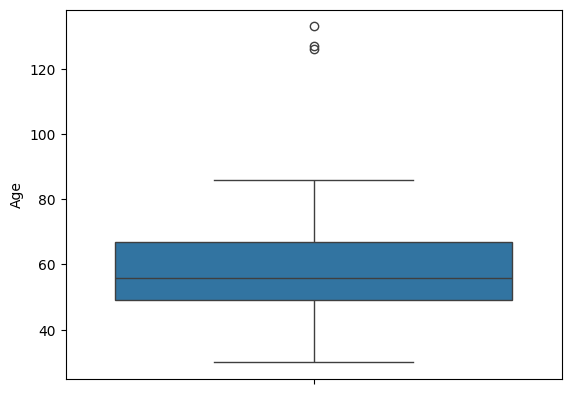

<Figure size 1000x800 with 0 Axes>

In [23]:
sns.boxplot(y=df["Age"])
plt.figure(figsize=(10,8))
plt.show()

In [24]:
print("data size with outliers:", len(df))

df = df[ (df["Age"] < 90) ]
df = df[ (df["Income"] < 600_000) ]

print("data size without outliers:", len(df))

data size with outliers: 2240
data size without outliers: 2212


In [25]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()

,0
Income,0.348028
Kidhome,0.636628
Teenhome,0.406329
Recency,-0.000688
MntWines,1.170977
MntFruits,2.103864
MntMeatProducts,2.027563
MntFishProducts,1.916558
MntSweetProducts,2.102925
MntGoldProds,1.837728


In [27]:
df["Education"].value_counts()

,count
Education,
Graduation,1115
PhD,480
Master,365
2n Cycle,198
Basic,54


In [28]:
df["Marital_Status"].value_counts()

,count
Marital_Status,
Married,857
Together,571
Single,470
Divorced,231
Widow,76
Alone,3
Absurd,2
YOLO,2


####  Feature Engineering  with Education

In [29]:
df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate", "PhD": "Postgraduate"
})

##### Feature Engineering with Marital_Status

In [30]:
df["Living_With"] = df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone", "Divorced": "Alone",
    "Widow": "Alone", "Absurd": "Alone", "YOLO": "Alone"
})

In [31]:
df["Living_With"].value_counts()

,count
Living_With,
Partner,1428
Alone,784


In [32]:
df[["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].head(0)

,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases


In [33]:
df[["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]].head()

,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
0,3,8,10,4,7
1,2,1,1,2,5
2,1,8,2,10,4
3,2,2,0,4,6
4,5,5,3,6,5


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2212 entries, 0 to 2239
Data columns (total 33 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Education              2212 non-null   object 
 1   Marital_Status         2212 non-null   object 
 2   Income                 2212 non-null   float64
 3   Kidhome                2212 non-null   int64  
 4   Teenhome               2212 non-null   int64  
 5   Recency                2212 non-null   int64  
 6   MntWines               2212 non-null   int64  
 7   MntFruits              2212 non-null   int64  
 8   MntMeatProducts        2212 non-null   int64  
 9   MntFishProducts        2212 non-null   int64  
 10  MntSweetProducts       2212 non-null   int64  
 11  MntGoldProds           2212 non-null   int64  
 12  NumDealsPurchases      2212 non-null   int64  
 13  NumWebPurchases        2212 non-null   int64  
 14  NumCatalogPurchases    2212 non-null   int64  
 15  NumStoreP

In [35]:
df["Education"].value_counts()

,count
Education,
Graduate,1115
Postgraduate,845
Undergraduate,252


In [36]:
original_features = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "Kidhome",
    "Teenhome",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response",
    "Marital_Status"
]

df = df.drop(columns=original_features)

In [37]:
df = df.drop_duplicates()

In [38]:
df.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebVisitsMonth', 'Complain', 'CustomerYear', 'CustomerMonth',
       'CustomerTenureDays', 'TotalSpend', 'TotalPurchases', 'TotalChildren',
       'TotalCampaignAccepted', 'Age', 'Living_With'],
      dtype='object')

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer,StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans

In [40]:
skew_feature = ["Income"]

numeric_feature = [
    'Recency',
    'NumDealsPurchases',
    'NumWebVisitsMonth',
    'Complain',
    'CustomerYear',
    'CustomerMonth',
    'CustomerTenureDays',
    'TotalSpend',
    'TotalPurchases',
    'TotalChildren',
    'TotalCampaignAccepted',
    'Age'
]
category_feature = ["Education","Living_With"]

In [41]:
from pandas.core.indexes import category
skew_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])

numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])
category_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [42]:
df.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebVisitsMonth', 'Complain', 'CustomerYear', 'CustomerMonth',
       'CustomerTenureDays', 'TotalSpend', 'TotalPurchases', 'TotalChildren',
       'TotalCampaignAccepted', 'Age', 'Living_With'],
      dtype='object')

In [43]:
preprocessor = ColumnTransformer(transformers=[
    ("skew", skew_pipeline, skew_feature),
    ("numeric", numeric_pipeline, numeric_feature),
    ("category", category_pipeline, category_feature)
])

In [44]:
print(df.columns.tolist())

['Education', 'Income', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Complain', 'CustomerYear', 'CustomerMonth', 'CustomerTenureDays', 'TotalSpend', 'TotalPurchases', 'TotalChildren', 'TotalCampaignAccepted', 'Age', 'Living_With']


In [45]:
print("Living_With" in df.columns)

True


#### Build Pipeline

In [46]:
clustering_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("kmeans", KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    ))
])



In [47]:
clustering_pipeline.fit(df)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Income']),
                                                 ('numeric',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Recency',
                                                   'NumDealsPurchases',
                                                   'NumWebVisitsMonth',
                                                   'Complain', 'CustomerYear',
                                                   'CustomerMonth',
                                                   'CustomerTenureDays',
                                                   'TotalSpend',
                                                   'TotalPurchases',
                                                   'TotalChildren',
                                                   'TotalCampaignAccepted',
                                                   'Age']),
                                                 ('category',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Education',
                                                   'Living_With'])])),
                ('kmeans', KMeans(n_clusters=4, n_init=10, random_state=42))])

In [48]:
df["Cluster"] =  clustering_pipeline.predict(df)

In [49]:
df["Cluster"].value_counts()

,count
Cluster,
1,813
0,667
3,528
2,19


#### Elbow Method

In [50]:
# Remove Cluster if it already exists
if "Cluster" in df.columns:
    df = df.drop(columns=["Cluster"])


# Transform the data using the same preprocessing used in K-Means
X_processed = preprocessor.fit_transform(df)

print("Processed data shape:", X_processed.shape)

Processed data shape: (2027, 18)


In [51]:
from sklearn.cluster import KMeans

inertias = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_processed)
    inertias.append(model.inertia_)

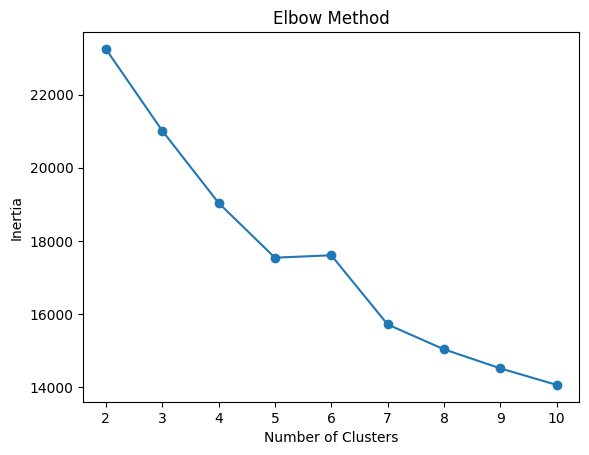

In [52]:
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [53]:
!pip install kneed

In [54]:
from kneed import KneeLocator

knee_locator = KneeLocator(
    range(2,11),
    inertias,
    curve="convex",
    direction="decreasing"
)

print("Optimal K according to Knee Locator:", knee_locator.elbow)

Optimal K according to Knee Locator: 5


#### Silhouette Score

In [55]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_processed)

    score = silhouette_score(X_processed, labels)

    print(k, score)

2 0.18438772811042553
3 0.15823168965959447
4 0.16494934626947602
5 0.143383736724219
6 0.13317229706704653
7 0.1393630897806651
8 0.13593398545989327
9 0.13167581752646135
10 0.13326775833348867


### Final Cluster

In [56]:
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("kmeans", KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    ))
])

final_pipeline.fit(df)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Income']),
                                                 ('numeric',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Recency',
                                                   'NumDealsPurchases',
                                                   'NumWebVisitsMonth',
                                                   'Complain', 'CustomerYear',
                                                   'CustomerMonth',
                                                   'CustomerTenureDays',
                                                   'TotalSpend',
                                                   'TotalPurchases',
                                                   'TotalChildren',
                                                   'TotalCampaignAccepted',
                                                   'Age']),
                                                 ('category',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Education',
                                                   'Living_With'])])),
                ('kmeans', KMeans(n_clusters=5, n_init=10, random_state=42))])

In [57]:
df["Cluster"] = final_pipeline.predict(df)

In [58]:
df["Cluster"].value_counts().sort_index()

,count
Cluster,
0,495
1,371
2,523
3,619
4,19


In [59]:
cluster_profile = df.groupby("Cluster").agg({
    "Income": "mean",
    "TotalSpend": "mean",
    "TotalPurchases": "mean",
    "Recency": "mean",
    "Age": "mean",
    'NumDealsPurchases':"mean",
    'NumWebVisitsMonth':"mean",
    'Complain':"mean",
    'CustomerYear':"mean",
    'CustomerMonth':"mean",
    'CustomerTenureDays':"mean",
    'TotalChildren':"mean",
    'TotalCampaignAccepted':"mean"
})

print(cluster_profile)

               Income   TotalSpend  TotalPurchases    Recency        Age  \
Cluster                                                                    
0        56982.717172   769.444444       17.058586  48.824242  61.052525   
1        44268.245283   207.530997        8.161725  48.107817  56.525606   
2        76255.413002  1344.244742       19.307839  48.942639  58.124283   
3        32543.239095   104.483037        5.957997  49.403877  53.453958   
4        46023.684211   409.789474       11.526316  48.578947  56.894737   

         NumDealsPurchases  NumWebVisitsMonth  Complain  CustomerYear  \
Cluster                                                                 
0                 4.290909           6.167677       0.0   2012.581818   
1                 2.040431           5.258760       0.0   2013.997305   
2                 1.108987           2.745698       0.0   2013.078394   
3                 1.988691           6.852989       0.0   2012.775444   
4                 2.368421   

#### Save The Model

In [60]:
import joblib

In [61]:
model_cluster = {
    "pipeline": final_pipeline,
    "reference_date": reference_date
}

joblib.dump(model_cluster,"customer_segmentation_pipeline.pkl")

['customer_segmentation_pipeline.pkl']

## Visualization after clustering

In [62]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_processed)

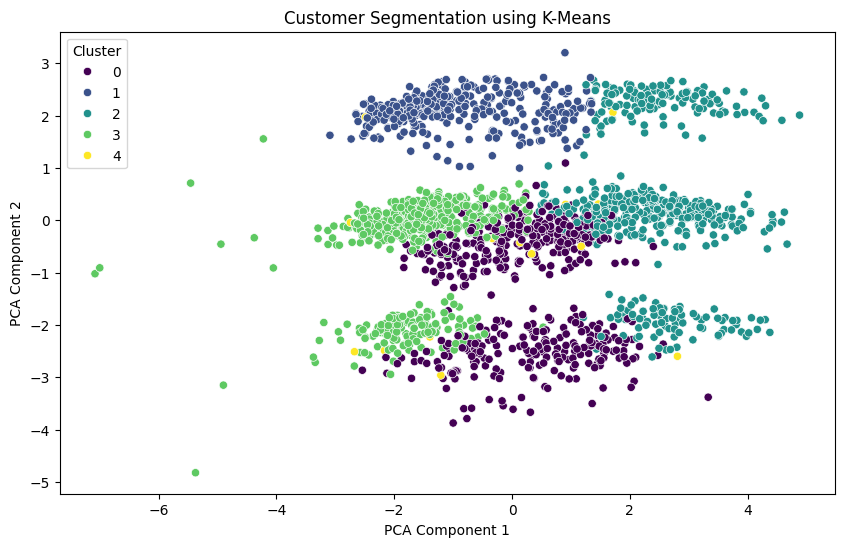

In [63]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["Cluster"],
    palette="viridis"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [64]:
print(pca.explained_variance_ratio_)

[0.24288428 0.17397038 0.09950532]


In [65]:
print(pca.explained_variance_ratio_.cumsum())

[0.24288428 0.41685466 0.51635998]
